In [11]:
!pip install nltk scikit-learn pandas numpy matplotlib seaborn ipywidgets -q

import numpy as np
import pandas as pd
import nltk
import re
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import wordpunct_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("Libraries imported successfully!")

Libraries imported successfully!


[nltk_data] Downloading package stopwords to /Users/apple/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/apple/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /Users/apple/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [12]:
data = {

    "symptoms": [
        "what are the symptoms of heart disease",
        "why do I feel chest pain",
        "what causes irregular heartbeat",
        "why am I experiencing shortness of breath",
        "what are signs of poor heart health",
        "why do I feel dizzy sometimes",
        "what does heart palpitations mean",
        "how to identify heart problems"
    ],

    "risk_factors": [
        "what causes heart disease",
        "does smoking affect the heart",
        "is high blood pressure dangerous",
        "how does cholesterol affect heart health",
        "does obesity increase heart disease risk",
        "can diabetes cause heart problems",
        "does family history affect heart health",
        "what are major cardiac risk factors"
    ],

    "diet": [
        "what foods are good for the heart",
        "which fruits improve heart health",
        "what is a heart healthy diet",
        "should I reduce salt intake",
        "are vegetables good for the heart",
        "which foods increase cholesterol",
        "is eating nuts good for heart health",
        "what foods should heart patients avoid"
    ],

    "exercise": [
        "what exercises improve heart health",
        "how much walking is good for the heart",
        "is jogging good for heart health",
        "how often should I exercise",
        "does cycling improve heart fitness",
        "what is the best cardio exercise",
        "can yoga improve heart health",
        "how does physical activity help the heart"
    ],

    "medication": [
        "what medicines are used for blood pressure",
        "what are cholesterol lowering medicines",
        "why do doctors prescribe statins",
        "what is the purpose of beta blockers",
        "can heart medicines have side effects",
        "why should I take prescribed heart medicines",
        "what are blood thinners",
        "should I stop taking heart medication"
    ],

    "emergency": [
        "what should I do during a heart attack",
        "someone has severe chest pain",
        "what are emergency signs of a heart attack",
        "person is having difficulty breathing",
        "what to do if someone collapses",
        "someone has sudden chest pressure and sweating",
        "how to respond to suspected cardiac arrest",
        "someone is unconscious and not breathing normally"
    ]
}

# Convert dictionary into DataFrame
rows = []

for intent, queries in data.items():
    for query in queries:
        rows.append({
            "query": query,
            "intent": intent
        })

df = pd.DataFrame(rows)

print(df)
print("\nTotal queries:", len(df))
print("\nIntent distribution:")
print(df['intent'].value_counts())

                                                query        intent
0              what are the symptoms of heart disease      symptoms
1                            why do I feel chest pain      symptoms
2                     what causes irregular heartbeat      symptoms
3           why am I experiencing shortness of breath      symptoms
4                 what are signs of poor heart health      symptoms
5                       why do I feel dizzy sometimes      symptoms
6                   what does heart palpitations mean      symptoms
7                      how to identify heart problems      symptoms
8                           what causes heart disease  risk_factors
9                       does smoking affect the heart  risk_factors
10                   is high blood pressure dangerous  risk_factors
11           how does cholesterol affect heart health  risk_factors
12           does obesity increase heart disease risk  risk_factors
13                  can diabetes cause heart pro

In [13]:
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

def preprocess(text):

    # 1. Lowercase conversion
    text = text.lower()

    # 2. Tokenization
    tokens = wordpunct_tokenize(text)

    # 3. Remove stopwords and punctuation
    tokens = [
        word for word in tokens
        if word.isalpha() and word not in stop_words
    ]

    # 4. Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return tokens


# Test preprocessing
sample = "What are the symptoms of Heart Diseases?"

print("Original:", sample)
print("Processed:", preprocess(sample))

Original: What are the symptoms of Heart Diseases?
Processed: ['symptom', 'heart', 'disease']


In [14]:
X = df['query']
y = df['intent']

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Create ML pipeline
model = Pipeline([

    ('tfidf', TfidfVectorizer(
        tokenizer=preprocess,
        token_pattern=None,
        lowercase=False
    )),

    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))

])

# Train model
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Model trained successfully!
Training samples: 36
Testing samples: 12


Accuracy: 0.5833333333333334
Precision: 0.5833333333333333
Recall: 0.5833333333333334
F1 Score: 0.5333333333333333

Classification Report:
              precision    recall  f1-score   support

        diet       0.33      0.50      0.40         2
   emergency       1.00      0.50      0.67         2
    exercise       0.00      0.00      0.00         2
  medication       1.00      0.50      0.67         2
risk_factors       0.67      1.00      0.80         2
    symptoms       0.50      1.00      0.67         2

    accuracy                           0.58        12
   macro avg       0.58      0.58      0.53        12
weighted avg       0.58      0.58      0.53        12



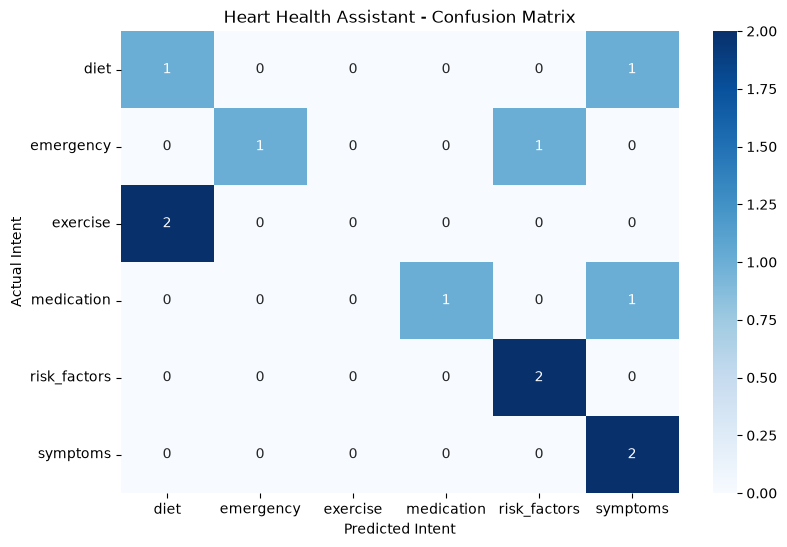

In [15]:
# Predictions
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

# Precision
precision = precision_score(
    y_test, y_pred, average='weighted', zero_division=0
)

# Recall
recall = recall_score(
    y_test, y_pred, average='weighted', zero_division=0
)

# F1 Score
f1 = f1_score(
    y_test, y_pred, average='weighted', zero_division=0
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Heart Health Assistant - Confusion Matrix")
plt.show()

In [16]:
knowledge_base = {

    "symptoms": """
    Common warning signs of heart problems may include chest
    discomfort, shortness of breath, unusual tiredness,
    dizziness and irregular heartbeat.

    Symptoms vary between individuals. Seek medical evaluation
    for concerning or persistent symptoms.
    """,

    "risk_factors": """
    Common cardiovascular risk factors include high blood
    pressure, high cholesterol, smoking, diabetes, obesity,
    physical inactivity and family history.

    Regular health checkups can help identify risk factors.
    """,

    "diet": """
    A heart-healthy eating pattern includes vegetables,
    fruits, whole grains, nuts and appropriate sources
    of lean protein.

    Limit excess salt, added sugar, saturated fats and
    highly processed foods.
    """,

    "exercise": """
    Regular physical activity supports cardiovascular health.

    Walking, cycling, swimming and other suitable aerobic
    activities can benefit heart health.

    Choose activity according to your health condition
    and seek medical advice before starting strenuous exercise.
    """,

    "medication": """
    Medicines such as statins, beta blockers and blood
    pressure medicines may be prescribed for specific
    cardiovascular conditions.

    Take medication only as prescribed by a qualified
    healthcare professional. Never stop or change
    medication without consulting your doctor.
    """,

    "emergency": """
    A suspected heart attack is a medical emergency.

    Warning signs can include chest pressure or discomfort,
    pain in the arms, back, neck or jaw, shortness of breath,
    cold sweating and nausea.

    Seek emergency medical assistance immediately.
    """
}

print("Knowledge base created successfully!")

Knowledge base created successfully!


In [17]:
# Emergency keywords
emergency_keywords = [
    "heart attack",
    "severe chest pain",
    "chest pressure",
    "difficulty breathing",
    "shortness of breath",
    "unconscious",
    "collapsed",
    "not breathing",
    "cardiac arrest",
    "cold sweat"
]

# Words indicating a heart-health query
domain_keywords = [
    "heart", "cardiac", "chest", "blood pressure",
    "cholesterol", "heartbeat", "pulse", "artery",
    "attack", "statin", "cardiovascular",
    "exercise", "diet", "smoking", "obesity",
    "diabetes", "medicine", "medication",
    "symptom", "breathing", "dizzy", "nutrition"
]

CONFIDENCE_THRESHOLD = 0.25


def is_emergency(query):

    query = query.lower()

    return any(
        keyword in query
        for keyword in emergency_keywords
    )


def is_heart_related(query):

    query = query.lower()

    return any(
        keyword in query
        for keyword in domain_keywords
    )

In [18]:
def heart_health_assistant(query):

    query = query.strip()

    if not query:
        return "Please enter a valid question."

    # Rule 1: Emergency escalation
    if is_emergency(query):

        return """
        EMERGENCY ALERT!

        Your query contains possible emergency symptoms.

        If someone is experiencing chest pressure, severe
        chest discomfort, difficulty breathing or unconsciousness,
        seek emergency medical assistance immediately.

        In India, call 112.

        Do not wait for this chatbot. Do not drive yourself
        to the hospital.

        This assistant cannot diagnose or treat emergencies.
        """

    # Rule 2: Unsupported query handling
    if not is_heart_related(query):

        return """
        Sorry, I can only answer questions related to
        heart health.

        You can ask about:
        - Heart symptoms
        - Risk factors
        - Diet and nutrition
        - Exercise
        - Medication
        - Heart emergencies
        """

    # Rule 3: Predict intent
    probabilities = model.predict_proba([query])[0]

    predicted_index = np.argmax(probabilities)

    intent = model.classes_[predicted_index]

    confidence = probabilities[predicted_index]

    print("Detected Intent:", intent)
    print("Confidence:", round(float(confidence), 3))

    # Rule 4: Low confidence handling
    if confidence < CONFIDENCE_THRESHOLD:

        return """
        I am not sufficiently confident about understanding
        your question.

        Please rephrase your question using clearer
        heart-health related words.
        """

    # Rule 5: Retrieve knowledge
    response = knowledge_base[intent]

    # Rule 6: Additional safety rules
    if intent == "medication":

        response += """

        IMPORTANT: Never start, stop or change medicines
        without consulting your doctor.
        """

    elif intent == "symptoms":

        response += """

        If symptoms are severe, sudden or worsening,
        seek urgent medical attention.
        """

    return response

In [19]:
# Test 1: One query from each intent
test_queries = [
    "what are the symptoms of heart disease",
    "does smoking increase heart disease risk",
    "which fruits are good for the heart",
    "is walking beneficial for heart health",
    "what are statins used for",
    "what should I do during a heart attack"
]

print("TESTING ALL SIX INTENTS")

for query in test_queries:

    print("\nUser:", query)

    response = heart_health_assistant(query)

    print("Assistant:", response)
    print("-" * 60)


# Test 2: Differently worded query
print("\nTEST 2: DIFFERENTLY WORDED QUERY")

query = "Can regular walks keep my heart healthy?"

print("User:", query)
print("Assistant:", heart_health_assistant(query))


# Test 3: Unsupported query
print("\nTEST 3: UNSUPPORTED QUERY")

query = "How can I repair my laptop?"

print("User:", query)
print("Assistant:", heart_health_assistant(query))


# Test 4: Low-confidence query
print("\nTEST 4: LOW CONFIDENCE QUERY")

# Temporarily increase threshold to demonstrate
old_threshold = CONFIDENCE_THRESHOLD
CONFIDENCE_THRESHOLD = 0.99

query = "heart xyz random terminology"

print("User:", query)
print("Assistant:", heart_health_assistant(query))

# Restore original threshold
CONFIDENCE_THRESHOLD = old_threshold


# Test 5: Emergency query
print("\nTEST 5: EMERGENCY QUERY")

query = "Someone is having severe chest pain and sweating"

print("User:", query)
print("Assistant:", heart_health_assistant(query))

TESTING ALL SIX INTENTS

User: what are the symptoms of heart disease
Detected Intent: symptoms
Confidence: 0.296
Assistant: 
    Common warning signs of heart problems may include chest
    discomfort, shortness of breath, unusual tiredness,
    dizziness and irregular heartbeat.

    Symptoms vary between individuals. Seek medical evaluation
    for concerning or persistent symptoms.
    

        If symptoms are severe, sudden or worsening,
        seek urgent medical attention.
        
------------------------------------------------------------

User: does smoking increase heart disease risk
Detected Intent: risk_factors
Confidence: 0.276
Assistant: 
    Common cardiovascular risk factors include high blood
    pressure, high cholesterol, smoking, diabetes, obesity,
    physical inactivity and family history.

    Regular health checkups can help identify risk factors.
    
------------------------------------------------------------

User: which fruits are good for the heart
Det

In [20]:
import ipywidgets as widgets

from IPython.display import display, clear_output

# Heading
title = widgets.HTML(
    value="""
    <h2 style='color:#1976D2'>
    Heart Health Information Assistant
    </h2>
    <p>Welcome! Ask me questions about heart health.</p>
    <p><b>Developed by:</b> Pranav Garg</p>
    <p><b>Roll Number:</b> 1024170298</p>
    """
)

# Input field
query_input = widgets.Text(
    placeholder="Enter your heart health question...",
    description="You:",
    layout=widgets.Layout(width="90%")
)

# Button
submit_button = widgets.Button(
    description="Ask Assistant",
    button_style="success",
    icon="send"
)

# Output area
output = widgets.Output()

# Function to process queries
def on_submit(button):

    query = query_input.value.strip()

    if not query:
        return

    with output:

        print("\nYou:", query)

        response = heart_health_assistant(query)

        print("\nAssistant:", response)

        print("\n" + "=" * 60)

    query_input.value = ""


# Connect button
submit_button.on_click(on_submit)

# Display interface
display(title, query_input, submit_button, output)

HTML(value="\n    <h2 style='color:#1976D2'>\n    Heart Health Information Assistant\n    </h2>\n    <p>Welcom…

Text(value='', description='You:', layout=Layout(width='90%'), placeholder='Enter your heart health question..…

Button(button_style='success', description='Ask Assistant', icon='send', style=ButtonStyle())

Output()